In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print("Dataset Shape:", data.shape)
print("\nColumn Names:")
print(data.columns.tolist())

display(data.head())

Dataset Shape: (2823, 25)

Column Names:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE', 'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE']


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [2]:
# Select numeric features for clustering
X = data[["QUANTITYORDERED", "PRICEEACH", "SALES"]]

print("Selected Features:")
display(X.head())

print("\nMissing Values:")
print(X.isnull().sum())

Selected Features:


,QUANTITYORDERED,PRICEEACH,SALES
0,30,95.70,2871.00
1,34,81.35,2765.90
2,41,94.74,3884.34
3,45,83.26,3746.70
4,49,100.00,5205.27



Missing Values:
QUANTITYORDERED    0
PRICEEACH          0
SALES              0
dtype: int64


In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled Data (first 5 rows):")
print(X_scaled[:5])

print("\nScaled Data Shape:", X_scaled.shape)

Scaled Data (first 5 rows):
[[-0.52289086  0.5969775  -0.37082523]
 [-0.11220131 -0.11445035 -0.42789707]
 [ 0.60650538  0.54938372  0.17944282]
 [ 1.01719493 -0.01975856  0.10470098]
 [ 1.42788447  0.81015797  0.89673966]]

Scaled Data Shape: (2823, 3)


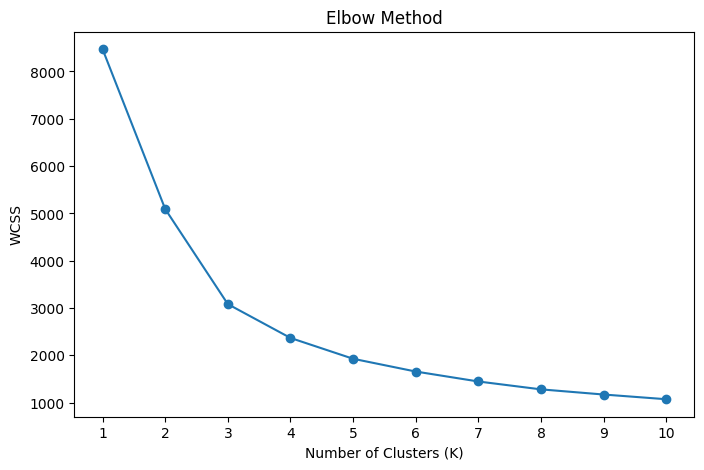

In [4]:
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.show()

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

data["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed.")
print("\nCluster Distribution:")
print(data["Cluster"].value_counts().sort_index())

display(data[["QUANTITYORDERED", "PRICEEACH", "SALES", "Cluster"]].head())

K-Means clustering completed.

Cluster Distribution:
Cluster
0     881
1     907
2    1035
Name: count, dtype: int64


,QUANTITYORDERED,PRICEEACH,SALES,Cluster
0,30,95.70,2871.00,2
1,34,81.35,2765.90,2
2,41,94.74,3884.34,1
3,45,83.26,3746.70,1
4,49,100.00,5205.27,1


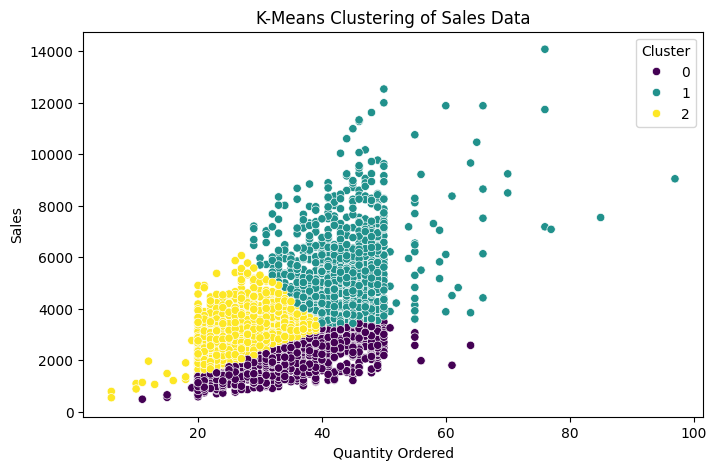

In [6]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x="QUANTITYORDERED",
    y="SALES",
    hue="Cluster",
    palette="viridis"
)

plt.title("K-Means Clustering of Sales Data")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.show()